# Playground - Part II

🎯 **Hedef**: ***Sinir Ağı hiperparametreleri*** hakkında daha iyi bir anlayış kazanmak

<hr>

👉  [Playground](https://playground.tensorflow.org/#activation=tanh&batchSize=10&dataset=circle&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=3&seed=0.06711&showTestData=false&discretize=false&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false&regularization_hide=false&regularizationRate_hide=false) tekrar açın. 

❗️ Algoritma stokastik olduğundan, sonuçların her çalıştırmada farklılık gösterebileceğini unutmayın. Bu nedenle, Sinir Ağlarınızın davranışını analiz etmek ve buna göre sonuçlarınızı çıkarmak için algoritmaları birden çok kez çalıştırmaktan çekinmeyin.

🕵🏻 Ders sırasında gördüğümüz farklı öğeleri inceleyelim:
- **Batch Size**
- **Regularization**
- **Learning Rate**

## (1) The batch size

❓ **İlk Soru** ❓ `circle dataset` (Sınıflandırma) seçin.

* Aşağıdakilerle bir model oluşturun:
* 3 nöronlu bir gizli katman,
* 0,03'e eşit bir a _learning rate_
* ve _tanh_ aktivasyon fonksiyonu

* Herhangi bir gürültü eklemeyin (=0).

* 30'luk bir batch size seçin

***Algoritmanın yakınsamasını inceleyin. Yavaş mı yoksa hızlı mı görünüyor?***

> Batch size 30 ile yakınsama **hızlı ve düzgün**: train ve test loss birkaç yüz epoch içinde istikrarlı şekilde düşüp sabitleniyor. Her güncelleme 30 örneğin ortalama gradyanını kullandığı için adımlar tutarlı. (3 nöronla çember bazen tam ayrılamayabilir; sonuç çalıştırmaya göre değişebilir.)

❓ **Soru: 1'lik batch size' da ne oluyor?** ❓

Şimdi, bu sinir ağını aynı veri kümesinde çalıştırın, ancak...

* batch-size 1 olsun.
* En az 150 dönem çalıştırdığınızdan emin olun.

***Eğitim ve test kaybı hakkında ne fark ettiniz? Bu istikrarsızlığın nedeni nedir?***

> Batch size 1 ile train ve test loss **zikzaklı ve kararsız** ilerliyor; sürekli inip çıkıyor. Sebebi: her ağırlık güncellemesi tek bir örneğin gradyanına göre yapılıyor (stochastic gradient descent). Tek bir örnek tüm veriyi iyi temsil etmediği için gradyan çok gürültülü; model her adımda farklı yöne çekiliyor.

❓ **Soru/Gözlem** ❓

Şimdi, tren kaybı ve test kaybı değerlerini okuyarak _batch_size_'ın etkisini görebilirsiniz: yinelemeleri duraklatın ve `“Adım”` düğmesini (play/stop düğmesinin sağ tarafında) kullanarak adım adım (yineleme başına yineleme) çalıştırın.

> Adım adım ilerlediğimizde batch size 1'de loss değerleri bir adımda düşüp bir sonrakinde yükselebiliyor; batch size 30'da ise her adımda daha düzenli ve küçük değişimler görülüyor. Büyük batch → daha stabil ama epoch başına daha az güncelleme; küçük batch → daha çok ve daha gürültülü güncelleme.

## 2. Regularization (Düzenleme)

❓ **Genelleme eksikliği hakkında soru** ❓ 

**Genelleme eksikliğini** bir kez daha gözlemlemek için:
* `“eXclusive OR”(XOR)` veri setini seçin, 
* gürültü seviyesi 50 olsun,
* 8 nöronlu iki gizli katman kullanın. 

***Modelinizi uyumlaştırmaya çalışın... Ne bekliyorsunuz?***

> Gürültü çok yüksek ve model fazla esnek olduğu için **overfitting** bekleniyor: model gürültülü noktaları da ayırmak için karar sınırını kıvrım kıvrım çiziyor. Train loss düşmeye devam ederken test loss bir noktadan sonra **yükseliyor** → model genelleme yapamıyor.

❗️ Daha küçük bir parti boyutu ile, modeliniz daha hızlı aşırı uyumlanacaktır... ❗️

👉 Bununla birlikte, bir sonraki soru için ***`batch size = 1`*** değerini koruyalım ve `düzenleme` (`regularization`) stratejisini kullanarak aşırı uyumlanmayı nasıl önleyebileceğimizi anlamaya çalışalım.

❓ **Düzenlemeyle (regularization) ilgili soru** ❓

Ağımızı ***avoid overfitting*** için ***düzenleyebilir miyiz***?

* Toplu işleme boyutunu 1 olarak tutun,
* Bir `L2-regularization` ekleyin,
* Karar sınırını düzeltene kadar bu L2 düzenlemesinin gücünü artırın!
Test kaybının artık dönemlerle birlikte artmadığını fark edin.

> L2 regularization büyük ağırlıkları cezalandırarak modeli daha basit kalmaya zorluyor. Gücü arttıkça karar sınırı yumuşadı ve XOR'un 4 bölgeli yapısına yaklaştı; test loss artık epoch'larla birlikte yükselmiyor, sabit kalıyor. Çok büyük bir değer seçilirse ise model underfit oluyor (sınır fazla basitleşiyor).

❓ **Spiral veri setiyle ilgili sorular** ❓

<u>Yapılandırma</u>:

* `spiral` veri setini seç,
* Regularization’ı kaldır,
* `training/test` veri oranını %80 eğitim olacak şekilde artır.

<u>Sinir Ağı</u>: 3 gizli katman:
* 1. katmanda 8 nöron,
* 2. katmanda 7 nöron,
* 3. katmanda 6 nöron.

<u>Deney</u>:

* Algoritmayı batch size = 30 ile çalıştır,
* En az 1500 epoch çalıştırdığından emin ol,
* Sonra aynı deneyi batch size = 1 ile yapıp karşılaştır.

Train loss ve test loss değerlerinde adım adım ne olduğuna bakabilirsin.

> Spiral zor bir veri seti. Batch size 30 ile model yavaş ama düzenli öğreniyor; train ve test loss birlikte düşüyor. Batch size 1 ile model çok daha hızlı öğreniyor ama loss değerleri çok dalgalı ve train loss test loss'tan belirgin şekilde ayrılıyor → küçük batch, gürültülü güncellemelerle modeli daha hızlı overfitting'e itiyor.

## (3) The learning rate (Öğrenme oranı)

<u>`circle veri setine`</u> geri dön:

* Gürültü (noise) olmadan,
* Eğitim / test veri oranı %50 olacak şekilde,
* Batch size = 20 kullan.

<u>Sinir ağı</u> ayarları:
* 5 nöronlu tek bir katman,
* Regularization yok,
* `tanh` aktivasyon fonksiyonu.

❓ **Learning rate ile ilgili soru** ❓

Her bir learning rate değeri için (0.0001’den 10’a kadar):
* Algoritmayı 1000 epoch boyunca çalıştır,
* Test loss değerlerini aşağıdaki listeye kaydet,
* Ardından test loss değerlerini learning rate’e göre çiz (plot).

❗️ <u>Uyarı</u> ❗️  
Learning rate’i her değiştirdiğinde sinir ağını mutlaka **yeniden başlat**  
(_play/pause tuşunun solundaki circular arrow_).

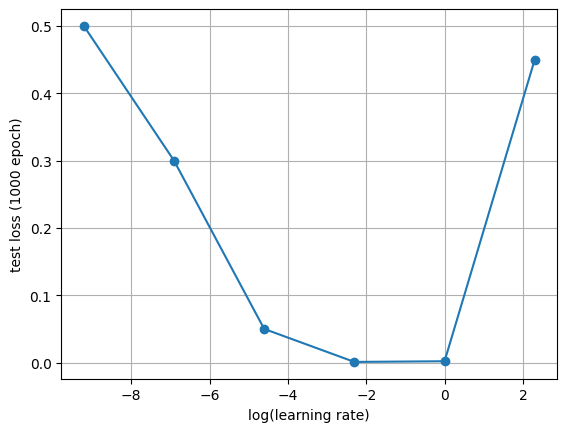

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline

import numpy as np

learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
test_loss = [0.50, 0.30, 0.05, 0.001, 0.002, 0.45]   # <- kendi Playground sonuçlarını yaz

plt.plot(np.log(learning_rates), test_loss, marker="o")
plt.xlabel("log(learning rate)")
plt.ylabel("test loss (1000 epoch)")
plt.grid();

❗️ <u>Uyarı</u> ❗️  
Hem **çok düşük** hem de **çok yüksek** learning rate değerleri yüksek test loss’a yol açar… fakat **farklı nedenlerle**!

* **Düşük learning rate**:
  - Sinir ağının, orta seviyedeki bir learning rate’e benzer şekilde yakınsamasını sağlar
  - Ancak **çok daha yavaş** olur → yani **daha fazla epoch** gerekir

* **Yüksek learning rate**:
  - Algoritmanın tamamen **dağılmasına (diverge)** neden olur
  - Örneğin learning rate \( \alpha = 10 \) ve 400 epoch dene:
    - Loss değerinin sürekli değiştiğini görürsün
    - Bu durum, algoritmanın **farklı yerel minimumlara** yakınsadığını gösterir

In [2]:
from tensorflow.keras import Sequential, Input, layers, regularizers, optimizers

# Playground'daki XOR + L2 regularization modelinin Keras karşılığı
model = Sequential([
    Input(shape=(2,)),                                                             # X1, X2
    layers.Dense(8, activation="tanh", kernel_regularizer=regularizers.l2(0.01)),  # L2 regularization
    layers.Dense(8, activation="tanh", kernel_regularizer=regularizers.l2(0.01)),
    layers.Dense(1, activation="sigmoid"),                                         # ikili sınıflandırma
])

model.compile(
    optimizer=optimizers.Adam(learning_rate=0.03),   # learning rate
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

# Eğitimde batch size ve epoch:
# model.fit(X_train, y_train, batch_size=1, epochs=150, validation_split=0.5)

2026-11-24 22:59:48.776863: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-24 22:59:48.777772: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 22:59:48.920027: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-24 22:59:48.974445: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-24 22:59:49.075495: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registe

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105 (420.00 B)

 Trainable params: 105 (420.00 B)

 Non-trainable params: 0 (0.00 B)

## Özet

- **Batch size:** Büyük batch → daha stabil ama daha yavaş öğrenme; küçük batch → gürültülü, dalgalı loss ve daha hızlı overfitting. Keras'ta `model.fit(..., batch_size=...)`.
- **Regularization:** L2, büyük ağırlıkları cezalandırarak overfitting'i önler; test loss'un yükselmesini durdurur. Keras'ta `kernel_regularizer=regularizers.l2(...)`.
- **Learning rate:** Çok küçük → çok yavaş yakınsama; çok büyük → loss dalgalanır ve ıraksar; ortada bir değer en iyisi. Keras'ta `optimizers.Adam(learning_rate=...)`.
- **Convergence vs overfitting:** Yakınsamada train ve test loss birlikte düşüp sabitlenir; overfitting'de train loss düşmeye devam ederken test loss yükselir.

🏁 Tebrikler!

💾 Not defterinizi `git add/commit/push` yapmayı unutmayın...